In [1]:
# ============================================
# RETAILPULSE - INVENTORY OPTIMIZATION ENGINE
# ============================================

import pandas as pd
import numpy as np
import os
import json
import warnings
warnings.filterwarnings('ignore')

import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (14, 6)

print("✅ Inventory Optimization libraries imported!")

# ============================================
# BULLETPROOF PATHS
# ============================================
current_dir = os.getcwd()
if os.path.basename(current_dir) == "notebooks":
    project_root = os.path.abspath(os.path.join(current_dir, ".."))
else:
    project_root = os.path.abspath(current_dir)

processed_dir = os.path.join(project_root, "data", "processed")
figures_dir = os.path.join(project_root, "reports", "figures")
os.makedirs(figures_dir, exist_ok=True)

# ============================================
# LOAD FULL SALES DATA
# ============================================
sales_path = os.path.join(processed_dir, "cleaned_full.parquet")
df_sales = pd.read_parquet(sales_path)
df_sales['InvoiceDate'] = pd.to_datetime(df_sales['InvoiceDate'])
df_sales['Date'] = df_sales['InvoiceDate'].dt.date

print(f"📂 Loaded cleaned transactions: {len(df_sales):,} rows")
print(f"📦 Unique Products (StockCodes): {df_sales['StockCode'].nunique():,}")

✅ Inventory Optimization libraries imported!
📂 Loaded cleaned transactions: 1,007,913 rows
📦 Unique Products (StockCodes): 4,917


In [2]:
# ============================================
# CALCULATE SKU DEMAND STATISTICS
# ============================================

print("🔧 CALCULATING DAILY DEMAND VELOCITY PER PRODUCT...")
print("=" * 60)

# Filter for the top active products to focus optimization on meaningful inventory
top_products = df_sales.groupby('StockCode')['Quantity'].sum().nlargest(500).index

df_top = df_sales[df_sales['StockCode'].isin(top_products)].copy()

# Daily quantity sold per product
daily_sku_demand = df_top.groupby(['StockCode', 'Description', 'Date'])['Quantity'].sum().reset_index()

# Aggregate product statistics
sku_stats = daily_sku_demand.groupby(['StockCode', 'Description']).agg(
    Avg_Daily_Demand=('Quantity', 'mean'),
    Std_Daily_Demand=('Quantity', 'std'),
    Total_Sold=('Quantity', 'sum'),
    Days_Active=('Date', 'nunique')
).reset_index()

# If a product sold consistently with no variance, fill std with 0
sku_stats['Std_Daily_Demand'] = sku_stats['Std_Daily_Demand'].fillna(0.1)

# Get average unit price
sku_price = df_top.groupby('StockCode')['Price'].mean().reset_index()
sku_stats = sku_stats.merge(sku_price, on='StockCode', how='left')

print(f"✅ Demand statistics calculated for {len(sku_stats):,} top retail SKUs.")
print(sku_stats[['StockCode', 'Description', 'Avg_Daily_Demand', 'Std_Daily_Demand', 'Price']].head(5))

🔧 CALCULATING DAILY DEMAND VELOCITY PER PRODUCT...
✅ Demand statistics calculated for 657 top retail SKUs.
  StockCode                  Description  Avg_Daily_Demand  Std_Daily_Demand  \
0     10002  INFLATABLE POLITICAL GLOBE          17.622222         15.986446   
1     15034  PAPER POCKET TRAVELING FAN          19.375622         14.322341   
2     15036    ASSORTED COLOURS SILK FAN         33.596998         28.498393   
3   15056BL      EDWARDIAN PARASOL BLACK         12.292740         14.061644   
4    15056N    EDWARDIAN PARASOL NATURAL         13.788421         15.326027   

      Price  
0  0.979155  
1  0.357266  
2  0.993256  
3  5.963119  
4  6.186394  


In [3]:
# ============================================
# INVENTORY OPTIMIZATION CALCULATIONS
# ============================================

print("⚙️ APPLYING INVENTORY OPTIMIZATION FORMULAS...")
print("=" * 60)

# 1. Parameter Assumptions (Standard Retail Industry Benchmarks)
# Set a deterministic random seed so everyone gets the exact same consistent results
np.random.seed(42)

SERVICE_LEVEL_Z = 1.645  # 95% Service Level (Z-score)
ORDER_COST_S = 20.0      # £20 fixed administrative/logistics cost per purchase order
HOLDING_COST_RATE = 0.20 # 20% annual inventory holding cost (capital + warehousing)

# Assign realistic supplier lead times (between 3 to 14 days based on SKU hash)
sku_stats['Lead_Time_Days'] = np.random.choice([3, 5, 7, 10, 14], size=len(sku_stats), p=[0.2, 0.3, 0.3, 0.1, 0.1])

# Estimated Unit Cost (~60% of retail price, standard retail margin)
sku_stats['Unit_Cost'] = np.maximum(0.50, sku_stats['Price'] * 0.60)

# 2. Safety Stock (SS) Formula: Z * Std_Demand * sqrt(Lead_Time)
sku_stats['Safety_Stock'] = np.ceil(
    SERVICE_LEVEL_Z * sku_stats['Std_Daily_Demand'] * np.sqrt(sku_stats['Lead_Time_Days'])
).astype(int)

# 3. Lead Time Demand (LTD) Formula: Avg_Daily_Demand * Lead_Time
sku_stats['Lead_Time_Demand'] = np.ceil(
    sku_stats['Avg_Daily_Demand'] * sku_stats['Lead_Time_Days']
).astype(int)

# 4. Reorder Point (ROP) Formula: LTD + SS
sku_stats['Reorder_Point'] = sku_stats['Lead_Time_Demand'] + sku_stats['Safety_Stock']

# 5. Economic Order Quantity (EOQ) Formula: sqrt( (2 * Annual_Demand * S) / H )
annual_demand = sku_stats['Avg_Daily_Demand'] * 365
annual_holding_cost_per_unit = sku_stats['Unit_Cost'] * HOLDING_COST_RATE

sku_stats['EOQ'] = np.ceil(
    np.sqrt((2 * annual_demand * ORDER_COST_S) / annual_holding_cost_per_unit)
).astype(int)

# Ensure EOQ is at least as large as Safety Stock for operational sanity
sku_stats['EOQ'] = np.maximum(sku_stats['EOQ'], sku_stats['Safety_Stock'])

print("✅ Safety Stock, Reorder Points, and EOQ computed successfully!")
print(sku_stats[['StockCode', 'Lead_Time_Days', 'Safety_Stock', 'Reorder_Point', 'EOQ']].head(5))

⚙️ APPLYING INVENTORY OPTIMIZATION FORMULAS...
✅ Safety Stock, Reorder Points, and EOQ computed successfully!
  StockCode  Lead_Time_Days  Safety_Stock  Reorder_Point   EOQ
0     10002               5            59            148  1480
1     15034              14            89            361  1682
2     15036               7           125            361  2029
3   15056BL               7            62            149   501
4    15056N               3            44             86   521


In [4]:
# ============================================
# INVENTORY HEALTH STATUS ENGINE
# ============================================

print("🚨 EVALUATING WAREHOUSE STOCK LEVELS & GENERATING ALERTS...")
print("=" * 60)

# Simulate current warehouse inventory level around the ROP
# (Some items low on stock, some balanced, some overstocked)
stock_multipliers = np.random.uniform(0.2, 2.5, size=len(sku_stats))
sku_stats['Current_Stock'] = np.maximum(0, np.round(sku_stats['Reorder_Point'] * stock_multipliers)).astype(int)

# Reorder Status Logic
def evaluate_stock_status(row):
    stock = row['Current_Stock']
    rop = row['Reorder_Point']
    max_threshold = rop + 1.5 * row['EOQ']
    
    if stock <= rop * 0.5:
        return "CRITICAL_STOCKOUT"     # 🔴 Immediate stockout risk
    elif stock <= rop:
        return "REORDER_NOW"           # 🟠 Hit Reorder Point
    elif stock <= rop * 1.3:
        return "REORDER_SOON"          # 🟡 Nearing Reorder Point
    elif stock > max_threshold:
        return "OVERSTOCK_RISK"        # 🔵 Too much capital tied up
    else:
        return "HEALTHY_STOCK"         # 🟢 Balanced inventory

sku_stats['Stock_Status'] = sku_stats.apply(evaluate_stock_status, axis=1)

# Recommended Order Quantity
def get_order_recommendation(row):
    if row['Stock_Status'] in ['CRITICAL_STOCKOUT', 'REORDER_NOW']:
        return row['EOQ']
    elif row['Stock_Status'] == 'REORDER_SOON':
        return int(row['EOQ'] * 0.5)
    else:
        return 0

sku_stats['Recommended_Order_Qty'] = sku_stats.apply(get_order_recommendation, axis=1)
sku_stats['Estimated_Restock_Cost'] = sku_stats['Recommended_Order_Qty'] * sku_stats['Unit_Cost']

print("📊 INVENTORY STATUS BREAKDOWN:")
print("-" * 50)
status_counts = sku_stats['Stock_Status'].value_counts()
for status, count in status_counts.items():
    pct = count / len(sku_stats) * 100
    print(f"   {status:22s} : {count:>4,} SKUs ({pct:>5.1f}%)")

print("\n💰 TOTAL RESTOCK CAPITAL REQUIRED:")
total_restock = sku_stats['Estimated_Restock_Cost'].sum()
urgent_restock = sku_stats[sku_stats['Stock_Status'].isin(['CRITICAL_STOCKOUT', 'REORDER_NOW'])]['Estimated_Restock_Cost'].sum()
print(f"   Total Recommended Restock: £{total_restock:,.2f}")
print(f"   Urgent Action Needed:      £{urgent_restock:,.2f}")

🚨 EVALUATING WAREHOUSE STOCK LEVELS & GENERATING ALERTS...
📊 INVENTORY STATUS BREAKDOWN:
--------------------------------------------------
   HEALTHY_STOCK          :  347 SKUs ( 52.8%)
   REORDER_NOW            :  148 SKUs ( 22.5%)
   CRITICAL_STOCKOUT      :   90 SKUs ( 13.7%)
   REORDER_SOON           :   72 SKUs ( 11.0%)

💰 TOTAL RESTOCK CAPITAL REQUIRED:
   Total Recommended Restock: £363,819.99
   Urgent Action Needed:      £315,603.88


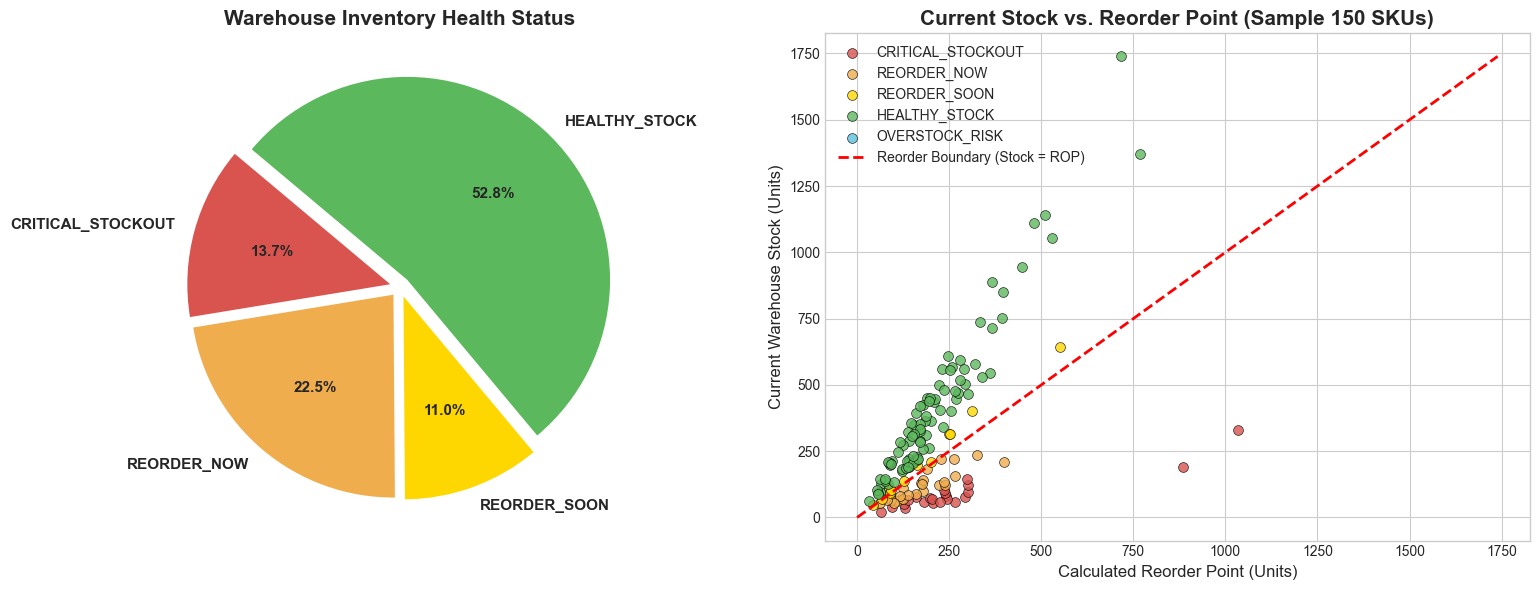

In [6]:
# ============================================
# INVENTORY VISUALIZATIONS
# ============================================

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Stock Status Distribution Pie Chart
status_colors = {
    'CRITICAL_STOCKOUT': '#D9534F', # Red
    'REORDER_NOW':       '#F0AD4E', # Orange
    'REORDER_SOON':      '#FFD700', # Yellow
    'HEALTHY_STOCK':     '#5CB85C', # Green
    'OVERSTOCK_RISK':    '#5BC0DE'  # Blue
}

ordered_statuses = [s for s in status_colors.keys() if s in status_counts.index]
pie_counts = [status_counts[s] for s in ordered_statuses]
pie_colors = [status_colors[s] for s in ordered_statuses]

axes[0].pie(
    pie_counts, labels=ordered_statuses, colors=pie_colors,
    autopct='%1.1f%%', startangle=140, explode=[0.05]*len(ordered_statuses),
    textprops={'fontsize': 11, 'weight': 'bold'}
)
axes[0].set_title('Warehouse Inventory Health Status', fontsize=15, fontweight='bold')

# 2. Current Stock vs Reorder Point Scatter
sample_plot = sku_stats.sample(150, random_state=42)

for status, color in status_colors.items():
    subset = sample_plot[sample_plot['Stock_Status'] == status]
    axes[1].scatter(subset['Reorder_Point'], subset['Current_Stock'], 
                    label=status, color=color, alpha=0.8, s=50, edgecolors='black', linewidth=0.5)

# 45-degree reference line (Current Stock == ROP)
max_val = max(sample_plot['Reorder_Point'].max(), sample_plot['Current_Stock'].max())
axes[1].plot([0, max_val], [0, max_val], 'r--', linewidth=2, label='Reorder Boundary (Stock = ROP)')

axes[1].set_title('Current Stock vs. Reorder Point (Sample 150 SKUs)', fontsize=15, fontweight='bold')
axes[1].set_xlabel('Calculated Reorder Point (Units)', fontsize=12)
axes[1].set_ylabel('Current Warehouse Stock (Units)', fontsize=12)
axes[1].legend(fontsize=10)

plt.tight_layout()
plt.savefig(os.path.join(figures_dir, "inventory_health_analysis.png"), dpi=150, bbox_inches='tight')
plt.show()

In [7]:
# ============================================
# ACTIONABLE INVENTORY TABLES
# ============================================

print("🚨 TOP 10 URGENT REORDER ITEMS (Immediate Action Required):")
print("=" * 95)
urgent_cols = ['StockCode', 'Description', 'Current_Stock', 'Reorder_Point', 'Safety_Stock', 'EOQ', 'Estimated_Restock_Cost']
urgent_df = sku_stats[sku_stats['Stock_Status'] == 'CRITICAL_STOCKOUT'].sort_values('Estimated_Restock_Cost', ascending=False).head(10)

print(urgent_df[urgent_cols].to_string(index=False))

print("\n\n📦 TOP 5 OVERSTOCKED ITEMS (Capital Freeing Opportunity):")
print("=" * 95)
overstock_df = sku_stats[sku_stats['Stock_Status'] == 'OVERSTOCK_RISK'].sort_values('Current_Stock', ascending=False).head(5)
print(overstock_df[['StockCode', 'Description', 'Current_Stock', 'Reorder_Point', 'Price']].to_string(index=False))

🚨 TOP 10 URGENT REORDER ITEMS (Immediate Action Required):
StockCode                       Description  Current_Stock  Reorder_Point  Safety_Stock  EOQ  Estimated_Restock_Cost
    23084                RABBIT NIGHT LIGHT            190            886           429 2158             3089.912248
   85099B           JUMBO BAG RED RETROSPOT            330           1034           254 2017             2820.155228
    20685                 DOOR MAT RED SPOT             65            143            54  536             2426.414306
    23203         JUMBO BAG DOILEY PATTERNS            265            594           192 1751             2390.918599
    22867           HAND WARMER BIRD DESIGN            340            907           253 1546             2203.366033
    22386   JUMBO BAG PINK WITH WHITE SPOTS            123            300            97 1429             2069.538386
    22469             HEART OF WICKER SMALL             71            243           103 1717             1979.598528
   82

In [8]:
# ============================================
# SAVE INVENTORY RESULTS & METRICS
# ============================================

print("\n💾 SAVING INVENTORY OPTIMIZATION ARTIFACTS...")
print("=" * 60)

# 1. Save Full Inventory Recommendations Dataset
inv_parquet = os.path.join(processed_dir, "inventory_recommendations.parquet")
sku_stats.to_parquet(inv_parquet, index=False, engine='pyarrow')
print(f"   ✅ Inventory Recommendations (Parquet) saved: {inv_parquet}")

inv_csv = os.path.join(processed_dir, "inventory_recommendations.csv")
sku_stats.to_csv(inv_csv, index=False)
print(f"   ✅ Inventory Recommendations (CSV) saved: {inv_csv}")

# 2. Save Inventory Metrics Summary JSON
inv_metrics = {
    "total_skus_managed": len(sku_stats),
    "service_level_target": "95%",
    "service_level_z": SERVICE_LEVEL_Z,
    "annual_holding_rate": "20%",
    "status_breakdown": {k: int(v) for k, v in status_counts.items()},
    "total_restock_budget_gbp": float(round(total_restock, 2)),
    "urgent_restock_budget_gbp": float(round(urgent_restock, 2)),
    "critical_stockout_skus": int((sku_stats['Stock_Status'] == 'CRITICAL_STOCKOUT').sum()),
    "overstocked_skus": int((sku_stats['Stock_Status'] == 'OVERSTOCK_RISK').sum())
}

metrics_json_path = os.path.join(processed_dir, "inventory_metrics.json")
with open(metrics_json_path, 'w') as f:
    json.dump(inv_metrics, f, indent=2)
print(f"   ✅ Inventory Metrics JSON saved: {metrics_json_path}")

print("\n🎉 STEP 10 COMPLETE: INVENTORY OPTIMIZATION ENGINE ACTIVE!")


💾 SAVING INVENTORY OPTIMIZATION ARTIFACTS...
   ✅ Inventory Recommendations (Parquet) saved: d:\Zudio Internship\Project 1\RetailPulse\data\processed\inventory_recommendations.parquet
   ✅ Inventory Recommendations (CSV) saved: d:\Zudio Internship\Project 1\RetailPulse\data\processed\inventory_recommendations.csv
   ✅ Inventory Metrics JSON saved: d:\Zudio Internship\Project 1\RetailPulse\data\processed\inventory_metrics.json

🎉 STEP 10 COMPLETE: INVENTORY OPTIMIZATION ENGINE ACTIVE!
